# 01 · Your first OBS–RCT comparison

**Question:** how do we turn one generated problem into an honest CATE comparison?

OBS means an observational sample; RCT means a randomized controlled trial. CATE is the conditional average treatment effect: the expected difference between treatment and control outcomes at the displayed covariates. MSM below refers to the marginal sensitivity model, which bounds hidden-dependent treatment selection.

We will inspect observed samples, fit three fixed baselines, score their predictions, and separate a target-CATE curve from the confounded OBS regression contrast. Edit the small configuration below and restart the kernel to explore. The default is a teaching run, not evidence for a method ranking.

Install the repository with `python -m pip install -e '.[baselines,notebooks]'` before opening this notebook. No data download, GPU or optional upstream method is required. See the [tutorial guide](README.md) for the learning path and execution instructions.


In [1]:
%matplotlib inline
from dataclasses import asdict, fields
import platform
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from obs_rct_benchmark import __version__
from obs_rct_benchmark.sensitivity import GammaDGPConfig, generate_gamma_problem, gamma_truth_at
from obs_rct_benchmark.methods import make_method
from obs_rct_benchmark.evaluation import cate_metrics
from obs_rct_benchmark.runner import method_seed

plt.rcParams.update({'figure.dpi': 105, 'font.size': 10})
print({'benchmark': __version__, 'python': platform.python_version(), 'numpy': np.__version__})


{'benchmark': '0.1.0a1', 'python': '3.11.16', 'numpy': '1.26.4'}


## Fix the problem before seeing scores

There are two displayed covariates and a fair binary hidden variable. Gamma bounds hidden treatment selection. Hidden outcome loadings and source CATE shifts are separate controls. The target covariates are standard Gaussian. Shifting the RCT covariate mean changes trial coverage while retaining Gaussian support and the same conditional target effect; it is not a hard positivity violation.

Here we use known simulation truth only after fitting. The independent RCT tuning set is available to a declared tuning rule, but these fixed baselines do not use it. We do not choose parameters or methods by their evaluation score.


In [2]:
DATA_SEED = 17
METHODS = ('rct_t_ridge', 'obs_t_ridge', 'naive_pooled_t_ridge')
config = GammaDGPConfig(
    name='first_comparison', d=2, gamma=3.0,
    hidden_loading0=0.4, hidden_loading1=1.0,
    obs_cate_shift=0.0, rct_covariate_shift=1.0,
    cate_complexity='smooth', noise_std=0.5,
    n_obs=240, n_rct_train=80, n_rct_tune=40,
    n_rct_test=40, n_eval=256,
)
problem = generate_gamma_problem(config, seed=DATA_SEED)
training = problem.training_view()
display(Markdown('| Setting | Value |\n|---|---|\n' + '\n'.join(
    f'| `{key}` | `{value}` |' for key, value in asdict(config).items()
)))


| Setting | Value |
|---|---|
| `name` | `first_comparison` |
| `n_obs` | `240` |
| `n_rct_train` | `80` |
| `n_rct_tune` | `40` |
| `n_rct_test` | `40` |
| `n_eval` | `256` |
| `n_target_reference` | `0` |
| `d` | `2` |
| `gamma_profile` | `constant` |
| `gamma` | `3.0` |
| `gamma_min` | `1.0` |
| `gamma_slope` | `1.0` |
| `gamma_intercept` | `0.0` |
| `observed_overlap` | `0.5` |
| `propensity_floor` | `0.02` |
| `hidden_loading0` | `0.4` |
| `hidden_loading1` | `1.0` |
| `bias_direction` | `1` |
| `obs_baseline_shift` | `0.0` |
| `obs_cate_shift` | `0.0` |
| `obs_covariate_shift` | `0.0` |
| `rct_covariate_shift` | `1.0` |
| `cate_complexity` | `smooth` |
| `cate_scale` | `1.0` |
| `noise_std` | `0.5` |
| `rct_propensity` | `0.5` |

## What can an estimator see?

`TrainingView` contains observed training/tuning roles and, only when requested, independent outcome-free target-reference covariates. Hidden variables, OBS oracle propensities and CATE truth belong to the evaluator. `eval_X` is supplied for prediction only; do not fit preprocessing or target adaptation on it.

The RCT test role is reserved for factual diagnostics. The current CATE score uses independent target evaluation covariates and their known CATE, not test outcomes.


In [3]:
assert not hasattr(training, 'truth')
assert not hasattr(training, 'rct_test')
assert training.obs_train.known_propensity is None
print('TrainingView fields:', [field.name for field in fields(training)])
print('Rows:', {role: getattr(training, role).n for role in ('obs_train', 'rct_train', 'rct_tune')})
print('Independent target-reference sample:', training.target_reference is not None)


TrainingView fields: ['obs_train', 'rct_train', 'rct_tune', 'target_reference']
Rows: {'obs_train': 240, 'rct_train': 80, 'rct_tune': 40}
Independent target-reference sample: False


## Inspect the observed sources

Outcome-versus-covariate scatterplots mix treatment, prognostic effects and noise. They are useful diagnostics but do not reveal individual causal effects. The histogram compares the first covariate only; coverage in this projection does not establish joint overlap.


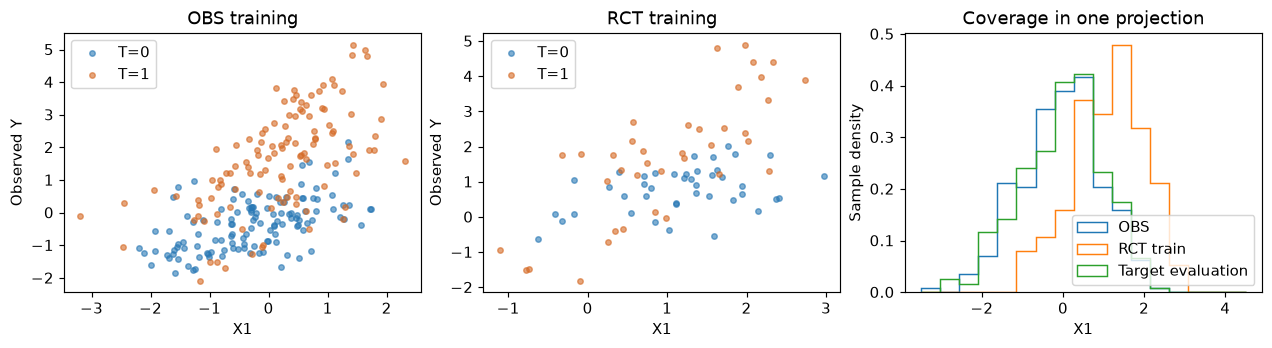

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), constrained_layout=True)
for ax, sample, title in zip(axes[:2], (training.obs_train, training.rct_train), ('OBS training', 'RCT training')):
    for arm, color in ((0, '#2878b5'), (1, '#d56a25')):
        rows = sample.T == arm
        ax.scatter(sample.X[rows, 0], sample.Y[rows], s=14, alpha=0.6, color=color, label=f'T={arm}')
    ax.set(xlabel='X1', ylabel='Observed Y', title=title)
    ax.legend()
bins = np.linspace(-3.5, 4.5, 18)
axes[2].hist(training.obs_train.X[:, 0], bins=bins, density=True, histtype='step', label='OBS')
axes[2].hist(training.rct_train.X[:, 0], bins=bins, density=True, histtype='step', label='RCT train')
axes[2].hist(problem.eval_X[:, 0], bins=bins, density=True, histtype='step', label='Target evaluation')
axes[2].set(xlabel='X1', ylabel='Sample density', title='Coverage in one projection')
axes[2].legend()
plt.show()


## Fit once per method; score outside the estimator

The T-learners fit separate outcome regressions in the two treatment arms, then subtract predictions. RCT-only uses randomized data, OBS-only ignores hidden confounding, and naive pooling ignores the source distinction. Each uses fixed standardized ridge defaults.

We append a declared query slice to the prediction rows so the same fit supplies both the independent evaluation predictions and the illustration. This does not allow fitting on those query rows. The slice fixes `X2=0`; it is not an average over the other covariate or a population performance score.


In [5]:
x1 = np.linspace(-3, 3, 121)
slice_X = np.column_stack((x1, np.zeros_like(x1)))
queries = np.vstack((problem.eval_X, slice_X))
predictions = {}
for method in METHODS:
    predictions[method] = make_method(method).fit_predict(
        training, queries, seed=method_seed('gamma:first_comparison', DATA_SEED, method)
    )
    assert predictions[method].shape == (len(queries),)
    assert np.isfinite(predictions[method]).all()

# Only the evaluator sees problem.eval_tau here.
scores = {method: cate_metrics(pred[:config.n_eval], problem.eval_tau)
          for method, pred in predictions.items()}
display(Markdown('| Method | CATE MSE | Root-PEHE |\n|---|---:|---:|\n' + '\n'.join(
    f'| `{method}` | {score["cate_mse"]:.4f} | {score["root_pehe"]:.4f} |'
    for method, score in scores.items()
)))
assert all(np.isclose(score['root_pehe'] ** 2, score['cate_mse']) for score in scores.values())


| Method | CATE MSE | Root-PEHE |
|---|---:|---:|
| `rct_t_ridge` | 1.3018 | 1.1410 |
| `obs_t_ridge` | 0.5884 | 0.7671 |
| `naive_pooled_t_ridge` | 0.3325 | 0.5766 |

## Distinguish the target from the OBS regression contrast

The following dashed curve is an **evaluator-only** quantity: `E[Y|T=1,X,OBS] − E[Y|T=0,X,OBS]`. It can differ from the target CATE because of hidden selection and source-specific outcomes. An OBS regression model may estimate that contrast well while estimating the target CATE poorly.


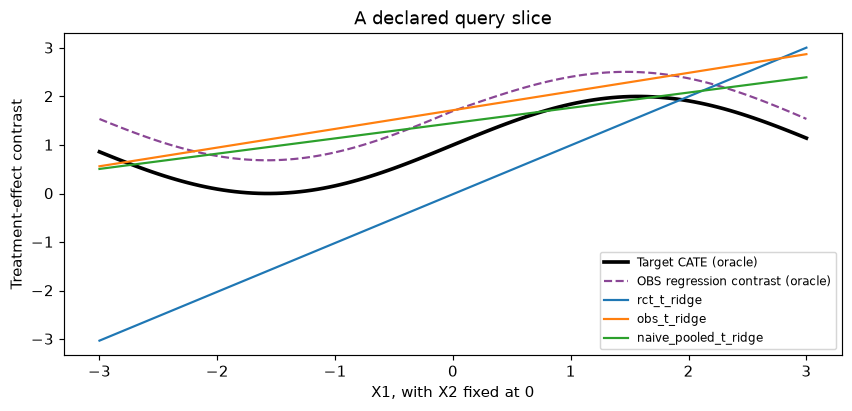

In [6]:
slice_truth = gamma_truth_at(slice_X, config)
obs_contrast = slice_truth['obs_conditional_mean_1'] - slice_truth['obs_conditional_mean_0']
fig, ax = plt.subplots(figsize=(8, 3.8), constrained_layout=True)
ax.plot(x1, slice_truth['tau_target'], color='black', linewidth=2.5, label='Target CATE (oracle)')
ax.plot(x1, obs_contrast, '--', color='#8a4695', label='OBS regression contrast (oracle)')
for method, pred in predictions.items():
    ax.plot(x1, pred[config.n_eval:], label=method)
ax.set(xlabel='X1, with X2 fixed at 0', ylabel='Treatment-effect contrast', title='A declared query slice')
ax.legend(fontsize=8)
plt.show()


## One overall score can conceal different regions

These predeclared target regions split at `X1=0`. We show their evaluation row counts and errors, not a confidence interval. A region with fewer trial observations can be harder, but a single small run cannot establish that coverage caused an observed error difference. Trial randomization, nuisance-model fit and target transportability remain separate issues.


| Target region | Eval rows | Method | CATE MSE |
|---|---:|---|---:|
| X1 < 0 | 118 | `rct_t_ridge` | 1.8961 |
| X1 < 0 | 118 | `obs_t_ridge` | 1.0161 |
| X1 < 0 | 118 | `naive_pooled_t_ridge` | 0.6554 |
| X1 >= 0 | 138 | `rct_t_ridge` | 0.7936 |
| X1 >= 0 | 138 | `obs_t_ridge` | 0.2226 |
| X1 >= 0 | 138 | `naive_pooled_t_ridge` | 0.0564 |

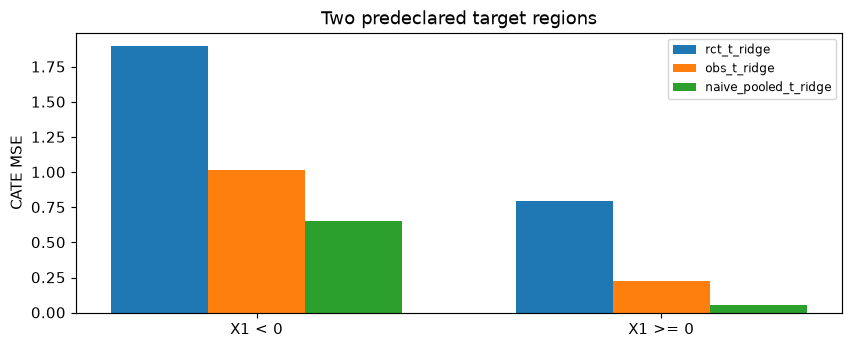

In [7]:
regions = {'X1 < 0': problem.eval_X[:, 0] < 0, 'X1 >= 0': problem.eval_X[:, 0] >= 0}
rows = []
for region, mask in regions.items():
    for method, pred in predictions.items():
        score = cate_metrics(pred[:config.n_eval][mask], problem.eval_tau[mask])
        rows.append((region, int(mask.sum()), method, score['cate_mse']))
display(Markdown('| Target region | Eval rows | Method | CATE MSE |\n|---|---:|---|---:|\n' + '\n'.join(
    f'| {region} | {n} | `{method}` | {mse:.4f} |' for region, n, method, mse in rows
)))
fig, ax = plt.subplots(figsize=(8, 3.2), constrained_layout=True)
for j, method in enumerate(METHODS):
    values = [row[3] for row in rows if row[2] == method]
    ax.bar(np.arange(2) + (j - 1) * 0.24, values, width=0.24, label=method)
ax.set(xticks=np.arange(2), xticklabels=list(regions), ylabel='CATE MSE', title='Two predeclared target regions')
ax.legend(fontsize=8)
plt.show()


## Change one assumption, then rerun from the top

Try `gamma=1.0`, zero hidden loadings, a nonzero `obs_cate_shift`, or `rct_covariate_shift=0.0` one at a time. State a prediction before running it. Keep all resulting conditions, including failures; do not retain only favorable method rankings. Repeating sample seeds measures variability within these chosen mechanisms, not generalization to unseen mechanisms.

Continue with [02 · Gamma and assumptions](02_gamma_and_assumptions.ipynb) to separate the mechanisms algebraically, or [04 · Custom methods and reproducibility](04_custom_method_and_reproducibility.ipynb) to use the full resumable runner. The [protocol](../docs/PROTOCOL.md) defines data access and scoring. This notebook uses the benchmark's original MSM construction, not a reproduction of a source paper's experiment; the [MSM documentation and references](../docs/SENSITIVITY.md) state its scope.
